# 02. MRP Baseline Run & Lot Sizing Analysis — ROLLINGMRP

This notebook demonstrates the Phase 1 Core MRP Engine:
1. **Full Factory Multi-Level MRP Run** across all 25 items and 12 planning periods
2. **Planned Order Releases** generated across Finished Goods, Subassemblies, and Raw Materials
3. **Time-Phased PAB Trajectories** demonstrating safety stock maintenance and order triggers
4. **Pegging Traceability Report** tracing raw material components up to MPS finished good lines
5. **Lot Sizing Policy Cost Comparison** (L4L vs. EOQ vs. Silver-Meal vs. Wagner-Whitin)

In [1]:
import sys
from pathlib import Path

# Ensure project root is in sys.path
current_dir = Path.cwd().resolve()
repo_root = current_dir if (current_dir / "src").exists() else current_dir.parent
if str(repo_root) not in sys.path:
    sys.path.insert(0, str(repo_root))

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from src.integration.load import run_pipeline
from src.core.netting import aggregate_gross_requirements
from src.core.explosion import BOMExplosionEngine
from src.core.lot_sizing import compute_lot_sizing

plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print("MRP Baseline environment configured successfully. Root:", repo_root)

MRP Baseline environment configured successfully. Root: C:\zendvalmics\project\rolling-mrp


## 1. Load Cleaned Factory Dataset & Initialize Inventory

In [2]:
data, quality_report = run_pipeline()
items_df = data["items"]
bom_df = data["bom"]
inv_df = data["inventory_initialized"]
mps_df = data["mps"]

periods = list(range(1, 13))
mps_dict = aggregate_gross_requirements(mps_df, periods)

inv_dict = {}
for _, row in inv_df.iterrows():
    inv_dict[str(row["item_id"])] = {
        "on_hand": float(row["quantity_on_hand"]),
        "allocated": float(row["quantity_allocated"]),
        "safety_stock": float(row["safety_stock"]),
        "lead_time_days": int(row["lead_time_days"]),
    }

print(f"Loaded {len(items_df)} items and {len(bom_df)} BOM edges across {len(periods)} planning periods.")

Loaded 25 items and 45 BOM edges across 12 planning periods.


## 2. Execute Multi-Level MRP Run (All 25 Items)

In [3]:
engine = BOMExplosionEngine(bom_df, items_df)
mrp_results, pegging_tracker = engine.run_multi_level_mrp(
    mps_gross_requirements=mps_dict,
    periods=periods,
    inventory_status=inv_dict,
)
print(f"Multi-level MRP completed successfully for {len(mrp_results)} items!")

# Aggregate all planned orders
all_orders = []
for itm, res in mrp_results.items():
    for po in res.planned_orders:
        all_orders.append({
            "item_id": po.item_id,
            "type": items_df.loc[items_df["item_id"] == po.item_id, "type"].values[0],
            "due_period": po.due_period,
            "release_period": po.release_period,
            "quantity": po.quantity,
            "past_due": po.past_due,
        })

df_orders = pd.DataFrame(all_orders)
print(f"Total Planned Orders Generated: {len(df_orders)}")
display(df_orders.head(15))

Multi-level MRP completed successfully for 25 items!
Total Planned Orders Generated: 268


,item_id,type,due_period,release_period,quantity,past_due
0,FG-03,finished_good,1,0,61.0,True
1,FG-03,finished_good,2,1,63.0,False
2,FG-03,finished_good,3,2,62.0,False
3,FG-03,finished_good,4,3,58.0,False
4,FG-03,finished_good,5,4,66.0,False
5,FG-03,finished_good,6,5,54.0,False
6,FG-03,finished_good,7,6,58.0,False
7,FG-03,finished_good,8,7,55.0,False
8,FG-03,finished_good,9,8,55.0,False
9,FG-03,finished_good,10,9,59.0,False


## 3. Planned Orders Breakdown by Item Classification

,Order Count,Total Units,Past Due Count
type,,,
finished_good,60,3108.000000,5
raw_material,120,121027.873757,27
subassembly,88,12495.243043,8


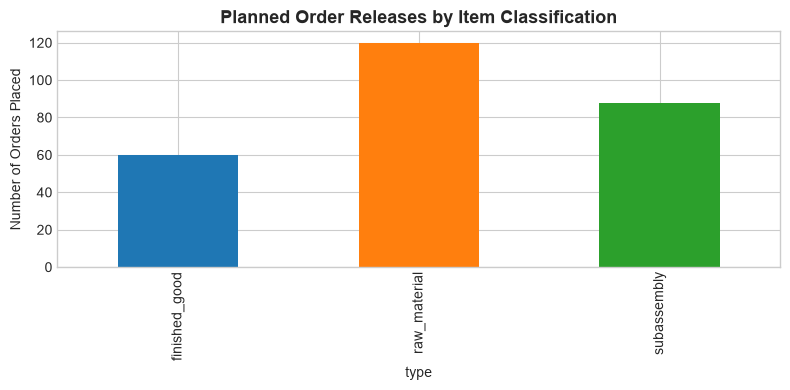

In [4]:
orders_by_type = df_orders.groupby("type").agg({
    "quantity": ["count", "sum"],
    "past_due": "sum"
})
orders_by_type.columns = ["Order Count", "Total Units", "Past Due Count"]
display(orders_by_type)

fig, ax = plt.subplots(figsize=(8, 4))
orders_by_type["Order Count"].plot(kind="bar", ax=ax, color=["#1f77b4", "#ff7f0e", "#2ca02c"])
ax.set_title("Planned Order Releases by Item Classification", fontsize=13, fontweight="bold")
ax.set_ylabel("Number of Orders Placed")
plt.tight_layout()
plt.show()

## 4. Time-Phased PAB Trajectories
Examine Projected Available Balance (PAB) trajectories against safety stock thresholds for finished good `FG-01` and common component `RM-01`.

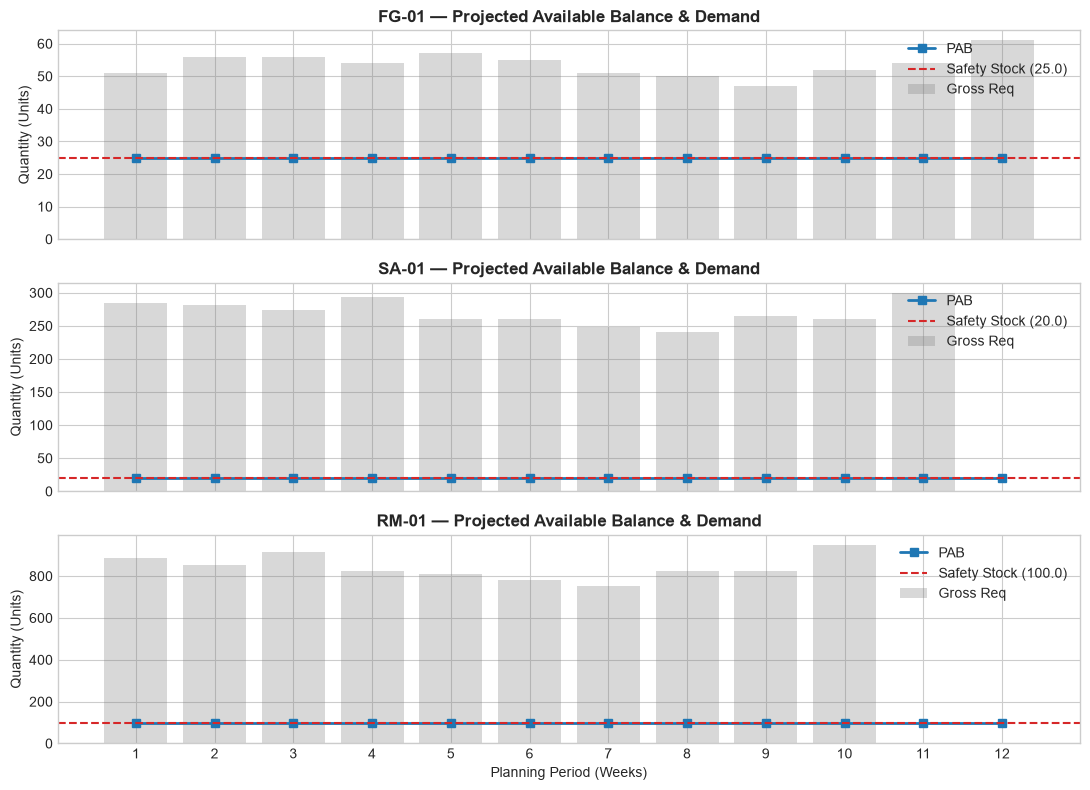

In [5]:
sample_items = ["FG-01", "SA-01", "RM-01"]
fig, axes = plt.subplots(len(sample_items), 1, figsize=(11, 8), sharex=True)

for idx, itm in enumerate(sample_items):
    res = mrp_results[itm]
    ax = axes[idx]
    ax.plot(res.periods, res.projected_available_balance, marker="s", label="PAB", color="#1f77b4", linewidth=2)
    ax.axhline(res.safety_stock, color="#d62728", linestyle="--", label=f"Safety Stock ({res.safety_stock})")
    ax.bar(res.periods, res.gross_requirements, alpha=0.3, color="#7f7f7f", label="Gross Req")
    ax.set_title(f"{itm} — Projected Available Balance & Demand", fontweight="bold")
    ax.set_ylabel("Quantity (Units)")
    ax.legend(loc="upper right")

axes[-1].set_xlabel("Planning Period (Weeks)")
plt.xticks(periods)
plt.tight_layout()
plt.show()

## 5. Pegging Traceability Report
Traceability showing which upstream parent demand drives component releases.

In [ ]:
pegging_df = pegging_tracker.generate_pegging_report()
print(f"Total Pegging Trace Records: {len(pegging_df)}")
print("Sample Upward Pegging for Common Component RM-01:")
display(pegging_df[pegging_df["child_item_id"] == "RM-01"].head(10))

## 6. Lot Sizing Policy Cost Comparison
Compare total inventory setup and holding costs across policies (L4L, EOQ, Silver-Meal, Wagner-Whitin) using classical dynamic demand.

In [ ]:
test_demand = [50.0, 60.0, 90.0, 70.0, 30.0, 100.0, 60.0, 40.0]
S = 100.0
h = 2.0

policies = ["L4L", "EOQ", "Silver_Meal", "Wagner_Whitin"]
comparison = []
for pol in policies:
    res = compute_lot_sizing(pol, test_demand, setup_cost=S, holding_cost=h)
    comparison.append({
        "Policy": pol,
        "Num Orders": sum(1 for q in res.orders if q > 0),
        "Setup Cost ($)": res.setup_cost,
        "Holding Cost ($)": res.holding_cost,
        "Total Cost ($)": res.total_cost,
        "Savings vs L4L (%)": round((800.0 - res.total_cost) / 800.0 * 100, 2)
    })

df_comp = pd.DataFrame(comparison)
display(df_comp)

fig, ax = plt.subplots(figsize=(8, 4))
df_comp.plot(x="Policy", y="Total Cost ($)", kind="bar", ax=ax, color="#2ca02c", legend=False)
ax.set_title("Total Policy Cost Comparison (Setup + Holding)", fontsize=13, fontweight="bold")
ax.set_ylabel("Total Cost ($)")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()